# UTS Graf Sains Data: Neo4j, VSM, Similarity, dan Rekomendasi KNN
**Nama / NIM:** Maria Sisilia S / 23031554168  |  **Dataset:** RetailRocket `events.csv`

Urutan kerja: **Konfigurasi → Tugas Pendahuluan → Persiapan Data → 2.1 Wrangling & EDA → 2.2 Analytics**.
fold : 20/05/2015	08/08/2015		09/08/2015	29/08/2015


In [1]:
URI  = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "sisiliams77")   
DB   = "neo4j"                     

DATA_DIR   = "data"
EVENTS_CSV = f"{DATA_DIR}/events.csv"
P1_CSV     = f"{DATA_DIR}/events_p1.csv"
P2_CSV     = f"{DATA_DIR}/events_p2.csv"

P1_START, P1_END = "2015-05-15", "2015-08-08"   # P1 = training
P2_START, P2_END = "2015-08-12", "2015-08-29"   # P2 = testing

SEED       = 42
WEIGHTS    = {"view": 1, "addtocart": 3, "transaction": 5}   # bobot interaksi untuk VSM
BATCH_SIZE = 5000
RESET_DB   = True    

In [2]:
import os, sys, math, zipfile, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from scipy import sparse
from sklearn.preprocessing import normalize
from tqdm.auto import tqdm
import neo4j
from neo4j import GraphDatabase, RoutingControl

print("neo4j driver:", neo4j.__version__)   

neo4j driver: 6.4.1


## 1. Tugas Pendahuluan
### 1.2 Tutorial driver Neo4j (Arthur, Guinevere, Lancelot, Merlin)

In [3]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_=DB,
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_=DB, routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH) as d:
    d.verify_connectivity()
    add_friend(d, "Arthur", "Guinevere")
    add_friend(d, "Arthur", "Lancelot")
    add_friend(d, "Arthur", "Merlin")
    print_friends(d, "Arthur")

Guinevere
Lancelot
Merlin


### Jawaban Pertanyaan Pendahuluan (Checkpoint)

**1. Nama database pada tutorial?**
`neo4j` (default), diberikan lewat argumen `database_="neo4j"` pada `execute_query`.

**2. Akses lain untuk mengakses database lain dalam 1 instance?**
- **Python driver:** `driver.session(database="namadb")`, atau `driver.execute_query(..., database_="namadb")`. Untuk DDL tingkat instance (misal `CREATE DATABASE`, `SHOW DATABASES`) dipakai `database="system"`.
- **Cypher / Neo4j Browser / cypher-shell:** klausa `USE namadb` (atau `:use namadb` di Browser), mis. `USE otherdb MATCH (n) RETURN n`.
- **DDL:** `CREATE DATABASE namadb`, `SHOW DATABASES`, `DROP DATABASE namadb`.
- Catatan: banyak database user dalam satu instance butuh Enterprise Edition (Neo4j Desktop memakai lisensi evaluasi Enterprise). Community Edition hanya `neo4j` + `system`.

**3. Jenis graf pertemanan yang dibuat?**
Property graph **berarah (directed)**, **unipartite/homogen** (satu label: `Person`), tanpa bobot, dengan satu jenis relasi `KNOWS`. Strukturnya star / ego-network: Arthur sebagai hub dengan out-degree 3, total 4 simpul dan 3 sisi, tanpa siklus (pohon berarah). `MERGE` membuat simpul dan relasi tidak duplikat saat dijalankan ulang.

In [4]:
# Reset isi database setelah tutorial
with GraphDatabase.driver(URI, auth=AUTH) as d:
    d.execute_query("MATCH (n) DETACH DELETE n", database_=DB)
print("Database dikosongkan.")

Database dikosongkan.


## Persiapan Data: unduh RetailRocket

In [5]:
os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.exists(EVENTS_CSV):
    zip_path = "ecommerce-dataset.zip"
    if not os.path.exists(zip_path):
        subprocess.run(
            ["curl.exe" if os.name == "nt" else "curl", "-L", "-o", zip_path,
             "https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset"],
            check=True)
    try:
        with zipfile.ZipFile(zip_path) as z:
            z.extract("events.csv", DATA_DIR)
    except zipfile.BadZipFile:
        raise SystemExit("File zip tidak valid. Unduh manual dari Kaggle dan taruh events.csv di folder data/.")
print("events.csv ada:", os.path.exists(EVENTS_CSV))

events.csv ada: True


## 2.1 Wrangling dan EDA
### No. 1: Eksplorasi awal & penentuan 2 periode (P1 = training, P2 = testing)

In [6]:
df = pd.read_csv(EVENTS_CSV)
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)

print("shape:", df.shape)
print("rentang:", df["datetime"].min(), "->", df["datetime"].max())
print(df["event"].value_counts(), "\n")
print("visitor unik:", df["visitorid"].nunique(), "| item unik:", df["itemid"].nunique())
print(df.groupby(df["datetime"].dt.strftime("%Y-%m")).size().rename("jumlah_event"))
df.head()

shape: (2756101, 6)
rentang: 2015-05-03 03:00:04.384000+00:00 -> 2015-09-18 02:59:47.788000+00:00
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64 

visitor unik: 1407580 | item unik: 235061
datetime
2015-05    590652
2015-06    610393
2015-07    697984
2015-08    553362
2015-09    303710
Name: jumlah_event, dtype: int64


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117000+00:00
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164000+00:00
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827000+00:00
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914000+00:00
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106000+00:00


### No. 2: Terapkan filter periode pada `timestamp`, simpan ke CSV

In [7]:
def filter_period(d, start, end):
    s, e = pd.Timestamp(start, tz="UTC"), pd.Timestamp(end, tz="UTC")
    return d[(d["datetime"] >= s) & (d["datetime"] < e)]

cols = ["timestamp", "visitorid", "event", "itemid", "transactionid"]
p1 = filter_period(df, P1_START, P1_END)[cols]
p2 = filter_period(df, P2_START, P2_END)[cols]
assert len(p1) > 0 and len(p2) > 0, "Periode kosong! Cek P1/P2 di sel konfigurasi."

p1.to_csv(P1_CSV, index=False)
p2.to_csv(P2_CSV, index=False)
print(f"P1 {P1_START}..{P1_END}: {len(p1):,} baris, {p1.visitorid.nunique():,} visitor, {p1.itemid.nunique():,} item")
print(f"P2 {P2_START}..{P2_END}: {len(p2):,} baris, {p2.visitorid.nunique():,} visitor, {p2.itemid.nunique():,} item")

P1 2015-05-15..2015-08-08: 1,798,360 baris, 921,303 visitor, 195,541 item
P2 2015-08-12..2015-08-29: 307,624 baris, 175,333 visitor, 82,603 item


### Impor P1 ke Neo4j (subgraph training)
Hanya **P1** yang diimpor ke graf. **P2** dipakai sebagai ground truth evaluasi (bagian 2.2).

Versi Cypher di bawah memakai `FOREACH + CASE` sebagai pengganti `CALL { ... UNION ALL ... }` 

In [12]:
from neo4j import GraphDatabase
d = GraphDatabase.driver(URI, auth=AUTH, connection_timeout=15)
d.execute_query("CREATE DATABASE uts IF NOT EXISTS WAIT", database_="system")
recs, _, _ = d.execute_query("SHOW DATABASES YIELD name, currentStatus", database_="system")
print([(r["name"], r["currentStatus"]) for r in recs])
d.close()

[('neo4j', 'quarantined'), ('system', 'online'), ('uts', 'online')]


In [13]:
DB = "uts"

In [14]:
driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

def q(cypher, **params):
    """Query baca -> DataFrame."""
    recs, _, _ = driver.execute_query(cypher, parameters_=params, database_=DB, routing_=RoutingControl.READ)
    return pd.DataFrame([r.data() for r in recs])

def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    FOREACH (_ IN CASE WHEN row.event = 'view' THEN [1] ELSE [] END |
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i))
    FOREACH (_ IN CASE WHEN row.event = 'addtocart' THEN [1] ELSE [] END |
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i))
    FOREACH (_ IN CASE WHEN row.event = 'transaction' THEN [1] ELSE [] END |
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i))
    """
    tx.run(cypher_query, batch=batch)

def to_records(chunk):
    out = []
    for r in chunk.itertuples(index=False):
        tid = None if pd.isna(r.transactionid) else int(r.transactionid)
        out.append({"timestamp": int(r.timestamp), "visitorid": int(r.visitorid),
                    "event": r.event, "itemid": int(r.itemid), "transactionid": tid})
    return out

if RESET_DB:
    with driver.session(database=DB) as s:
        s.run("MATCH (n) CALL { WITH n DETACH DELETE n } IN TRANSACTIONS OF 10000 ROWS")

total_rows = len(pd.read_csv(P1_CSV, usecols=["timestamp"]))
total_chunks = math.ceil(total_rows / BATCH_SIZE)

with driver.session(database=DB) as session:
    create_constraints(session)
    chunks = pd.read_csv(P1_CSV, chunksize=BATCH_SIZE)
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        session.execute_write(import_batch, to_records(chunk))
print("Proses impor berhasil.")

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (n) { ... }', position=<SummaryInputPosition line=1, column=11, offset=10>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 10, 'line': 1, 'column': 11}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: 'MATCH (n) CALL { WITH n DETACH DELETE n } IN TRANSACTIONS OF 10000 ROWS'


Mengimpor Batch Data:   0%|          | 0/360 [00:00<?, ?it/s]

Proses impor berhasil.


### No. 3: Komposisi subgraph (jenis & jumlah simpul) dengan Python API
Penjelasan Cypher:
- `MATCH (n)` mencocokkan **semua simpul**; `labels(n)[0]` mengambil label (Visitor/Item); `count(n)` menghitung simpul per label (agregasi implisit `GROUP BY` label).
- `MATCH ()-[r]->()` mencocokkan **semua relasi berarah**; `type(r)` memberi jenis relasi (VIEWED, ADDED_TO_CART, BOUGHT).
- `ORDER BY jumlah DESC` mengurutkan dari yang terbanyak.

In [15]:
Q_NODES = "MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah ORDER BY jumlah DESC"
Q_RELS  = "MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(r) AS jumlah ORDER BY jumlah DESC"
nodes_df, rels_df = q(Q_NODES), q(Q_RELS)
display(nodes_df); display(rels_df)

,jenis_simpul,jumlah
0,Visitor,921303
1,Item,195541


,jenis_relasi,jumlah
0,VIEWED,1739212
1,ADDED_TO_CART,44482
2,BOUGHT,14666


### No. 4 & 5: Vector Space Modelling (VSM)
Graf bipartit Visitor→Item dijadikan matriks interaksi **A** berukuran (user × item). Nilai sel = jumlah bobot interaksi (view=1, addtocart=3, transaction=5).
- **VSM User**: tiap user = vektor berdimensi `n_item` (baris A).
- **VSM Item**: tiap item = vektor berdimensi `n_user` (kolom A, atau baris dari Aᵀ).

In [16]:
Q_EDGES = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN v.visitorId AS visitorId, i.itemId AS itemId,
       sum(CASE type(r) WHEN 'VIEWED' THEN $wv WHEN 'ADDED_TO_CART' THEN $wa ELSE $wb END) AS w
"""
edges = q(Q_EDGES, wv=WEIGHTS["view"], wa=WEIGHTS["addtocart"], wb=WEIGHTS["transaction"])

u_codes, u_uni = pd.factorize(edges["visitorId"]); u_ids = pd.Index(u_uni)
i_codes, i_uni = pd.factorize(edges["itemId"]);    i_ids = pd.Index(i_uni)
A = sparse.csr_matrix((edges["w"].astype(float).values, (u_codes, i_codes)),
                      shape=(len(u_ids), len(i_ids)))
At = A.T.tocsr()          # item x user
print("A (user x item):", A.shape, "| At (item x user):", At.shape)

A (user x item): (921303, 195541) | At (item x user): (195541, 921303)


,VSM User
VSM,User (baris A)
jumlah vektor,921303
dimensi,195541
shape,"(921303, 195541)"
nnz,1398277
density,0.000008
sparsity (%),99.999224
nnz/vektor rata2,1.517717
nnz/vektor median,1.0
nnz/vektor maks,2838


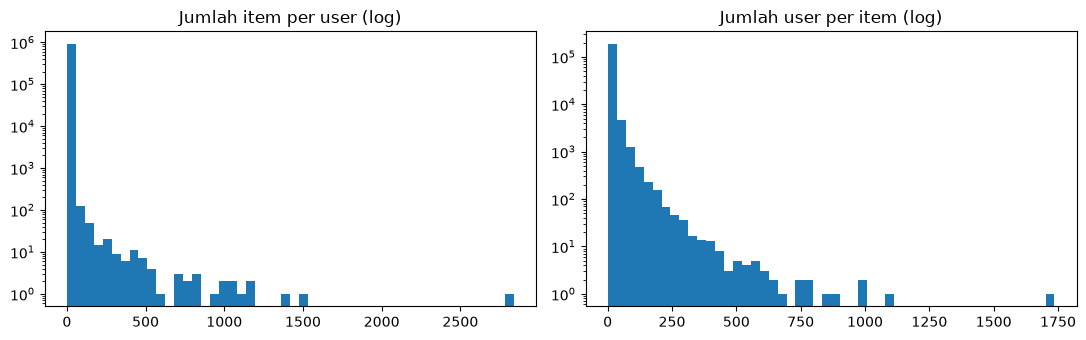

In [17]:
def describe_vsm(M, name):
    M = M.tocsr()
    rown = np.diff(M.indptr)
    n, d = M.shape
    return {"VSM": name, "jumlah vektor": n, "dimensi": d, "shape": str(M.shape),
            "nnz": M.nnz, "density": M.nnz / (n * d), "sparsity (%)": 100 * (1 - M.nnz / (n * d)),
            "nnz/vektor rata2": rown.mean(), "nnz/vektor median": float(np.median(rown)),
            "nnz/vektor maks": rown.max(), "% vektor dgn 1 nnz": 100 * (rown == 1).mean()}

vsm_user, vsm_item = describe_vsm(A, "User (baris A)"), describe_vsm(At, "Item (baris At)")
display(pd.DataFrame([vsm_user]).T.rename(columns={0: "VSM User"}))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(np.diff(A.indptr), bins=50, log=True);  ax[0].set_title("Jumlah item per user (log)")
ax[1].hist(np.diff(At.indptr), bins=50, log=True); ax[1].set_title("Jumlah user per item (log)")
plt.tight_layout(); plt.show()

In [18]:
# Sampel subgraph untuk plot networkx (graf penuh terlalu besar untuk digambar)
def sample_bipartite(A, n_users=25, min_item_deg=2, seed=SEED):
    rng = np.random.default_rng(seed)
    Acsc = A.tocsc()
    item_deg = np.diff(Acsc.indptr)
    seed_item = rng.choice(np.argsort(-item_deg)[:50])          # item populer sebagai jangkar
    cand = Acsc.indices[Acsc.indptr[seed_item]:Acsc.indptr[seed_item + 1]]
    users = rng.choice(cand, size=min(n_users, len(cand)), replace=False)
    sub = A[users]
    deg = np.asarray((sub > 0).sum(axis=0)).ravel()
    items = np.flatnonzero(deg >= min_item_deg)
    sub = sub[:, items].tocoo()
    un = [f"u{u}" for u in users]; inn = [f"i{i}" for i in items]
    B = nx.Graph()
    B.add_nodes_from(un, bipartite=0); B.add_nodes_from(inn, bipartite=1)
    for r, c, w in zip(sub.row, sub.col, sub.data):
        B.add_edge(un[r], inn[c], weight=float(w))
    B.remove_nodes_from(list(nx.isolates(B)))
    un = [n for n in un if n in B]; inn = [n for n in inn if n in B]
    return B, un, inn

def draw(G, title, color, node_list=None, bip=None):
    plt.figure(figsize=(8, 5.5))
    pos = nx.spring_layout(G, seed=SEED)
    if bip:
        un, inn = bip
        nx.draw_networkx_nodes(G, pos, nodelist=un, node_color="tab:blue", node_size=110, label="User")
        nx.draw_networkx_nodes(G, pos, nodelist=inn, node_color="tab:orange", node_shape="s", node_size=110, label="Item")
        plt.legend()
    else:
        nx.draw_networkx_nodes(G, pos, node_color=color, node_size=110)
    nx.draw_networkx_edges(G, pos, alpha=0.35)
    plt.title(title); plt.axis("off"); plt.show()

B, un, inn = sample_bipartite(A)
print(f"Sampel bipartit: {len(un)} user, {len(inn)} item, {B.number_of_edges()} sisi")

Sampel bipartit: 25 user, 4 item, 34 sisi


**No. 4: VSM User.** Ringkasan karakteristik di tabel (dimensi = jumlah item, shape = user × item, sparsity), lalu plot sampel.

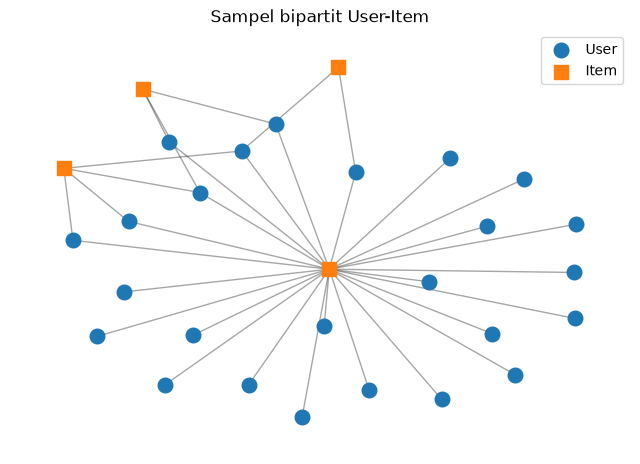

Proyeksi User-User (sampel): node = 25 | edge = 300 | density = 1.0


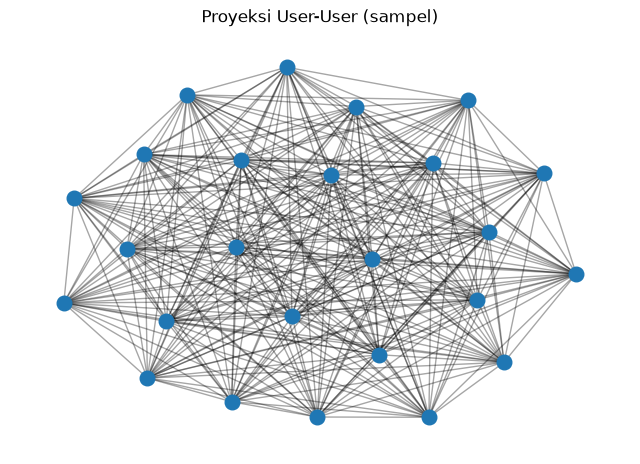

In [19]:
draw(B, "Sampel bipartit User-Item", None, bip=(un, inn))
GU = nx.bipartite.weighted_projected_graph(B, un)
print("Proyeksi User-User (sampel): node =", GU.number_of_nodes(), "| edge =", GU.number_of_edges(),
      "| density =", round(nx.density(GU), 3))
draw(GU, "Proyeksi User-User (sampel)", "tab:blue")

**No. 5: VSM Item.** Vektor item berdimensi = jumlah user.

,VSM Item
VSM,Item (baris At)
jumlah vektor,195541
dimensi,921303
shape,"(195541, 921303)"
nnz,1398277
density,0.000008
sparsity (%),99.999224
nnz/vektor rata2,7.150812
nnz/vektor median,2.0
nnz/vektor maks,1736


Proyeksi Item-Item (sampel): node = 4 | edge = 5 | density = 0.833


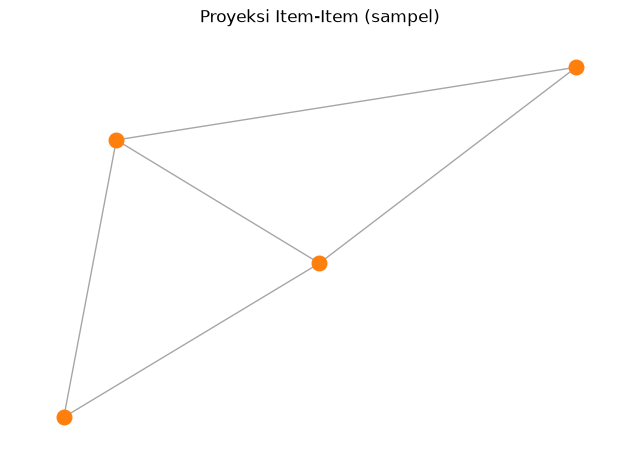

In [20]:
display(pd.DataFrame([vsm_item]).T.rename(columns={0: "VSM Item"}))
GI = nx.bipartite.weighted_projected_graph(B, inn)
print("Proyeksi Item-Item (sampel): node =", GI.number_of_nodes(), "| edge =", GI.number_of_edges(),
      "| density =", round(nx.density(GI), 3))
draw(GI, "Proyeksi Item-Item (sampel)", "tab:orange")

### No. 6: Proyeksi mana yang lebih efektif/efisien?
Ukuran biaya proyeksi: jumlah node, jumlah "wedge" (pasangan simpul yang berbagi tetangga, batas atas jumlah sisi proyeksi), dan memori matriks similarity penuh.

In [21]:
du = np.diff(A.indptr).astype(float)    # derajat user
di = np.diff(At.indptr).astype(float)   # derajat item
wedges_user = float((di * (di - 1) / 2).sum())   # sisi potensial User-User (berbagi item)
wedges_item = float((du * (du - 1) / 2).sum())   # sisi potensial Item-Item (berbagi user)

cmp = pd.DataFrame({
    "node": [A.shape[0], A.shape[1]],
    "wedge (batas atas sisi)": [wedges_user, wedges_item],
    "pasangan penuh n(n-1)/2": [A.shape[0] * (A.shape[0] - 1) / 2, A.shape[1] * (A.shape[1] - 1) / 2],
    "memori matriks sim penuh (GB, float32)": [A.shape[0] ** 2 * 4 / 1e9, A.shape[1] ** 2 * 4 / 1e9],
}, index=["User-User", "Item-Item"])
display(cmp)

PROJ = "item" if wedges_item < wedges_user else "user"   # bisa di-override manual setelah analisis
print("Proyeksi terpilih otomatis:", PROJ)

,node,wedge (batas atas sisi),pasangan penuh n(n-1)/2,"memori matriks sim penuh (GB, float32)"
User-User,921303,41061668.0,4.243991e+11,3395.196871
Item-Item,195541,19787023.0,1.911804e+10,152.945131


Proyeksi terpilih otomatis: item


### No. 7: Similarity pada graf terproyeksi (cosine)
Cosine dihitung dari VSM proyeksi terpilih. Skor top-K tetangga disimpan sebagai relasi `:SIMILAR {score}` di Neo4j untuk subset entitas terpopuler (menulis seluruh pasangan terlalu besar).

In [22]:
CFG = {"item": dict(label="Item",    key="itemId",    other="Visitor", okey="visitorId"),
       "user": dict(label="Visitor", key="visitorId", other="Item",    okey="itemId")}
C = CFG[PROJ]
M      = At if PROJ == "item" else A          # baris = entitas yang dibandingkan
ent_ids = i_ids if PROJ == "item" else u_ids
Mn = normalize(M, norm="l2")                  # cosine = dot product pada vektor ter-normalisasi
deg = np.diff(M.indptr)

def topk_cosine(Mn, rows, K=10, chunk=50):
    out = []
    for s in range(0, len(rows), chunk):
        r = np.asarray(rows[s:s + chunk])
        S = (Mn[r] @ Mn.T).toarray()
        S[np.arange(len(r)), r] = -1                      # buang diri sendiri
        idx = np.argpartition(-S, K, axis=1)[:, :K]
        for a, ix in enumerate(idx):
            for b in ix[np.argsort(-S[a, ix])]:
                out.append((int(r[a]), int(b), float(S[a, b])))
    return out

N_WRITE, K_SIM = 500, 10
REF_IDX = int(np.argmax(deg))                              # record acuan: entitas paling populer
REF_ID  = int(ent_ids[REF_IDX])
subset  = list(dict.fromkeys([REF_IDX] + list(np.argsort(-deg)[:N_WRITE])))
triples = topk_cosine(Mn, subset, K=K_SIM)
print(f"Proyeksi {PROJ}-{PROJ} | acuan {C['label']} {REF_ID} | {len(triples)} pasangan similarity dihitung")

Proyeksi item-item | acuan Item 5411 | 5000 pasangan similarity dihitung


In [23]:
def rel_counts():
    return q("MATCH ()-[r]->() RETURN type(r) AS relasi, count(r) AS jumlah ORDER BY relasi").set_index("relasi")["jumlah"]
before_counts = rel_counts()

# (b) Tulis similarity ke graf
rows = [{"a": int(ent_ids[a]), "b": int(ent_ids[b]), "score": round(s, 6)} for a, b, s in triples if s > 0]
WRITE_Q = f"""
UNWIND $rows AS row
MATCH (a:{C['label']} {{{C['key']}: row.a}}), (b:{C['label']} {{{C['key']}: row.b}})
MERGE (a)-[s:SIMILAR]->(b)
SET s.score = row.score, s.method = 'cosine'
"""
with driver.session(database=DB) as session:
    for s in range(0, len(rows), 5000):
        session.execute_write(lambda tx, part: tx.run(WRITE_Q, rows=part), rows[s:s + 5000])
print("SIMILAR ditulis:", len(rows))

SIMILAR ditulis: 5000


**7a. CYPHER top-5 similarity dari record acuan, 7b. hasil query pada graf yang sudah ditulis:**

In [24]:
Q_TOP5 = f"""
MATCH (a:{C['label']} {{{C['key']}: $ref}})-[s:SIMILAR]->(b:{C['label']})
RETURN a.{C['key']} AS acuan, b.{C['key']} AS tetangga, s.score AS similarity
ORDER BY similarity DESC LIMIT 5
"""
print(Q_TOP5)
display(q(Q_TOP5, ref=REF_ID))


MATCH (a:Item {itemId: $ref})-[s:SIMILAR]->(b:Item)
RETURN a.itemId AS acuan, b.itemId AS tetangga, s.score AS similarity
ORDER BY similarity DESC LIMIT 5



,acuan,tetangga,similarity
0,5411,33030,0.148574
1,5411,37807,0.103283
2,5411,33956,0.102651
3,5411,256242,0.087303
4,5411,459936,0.083055


### No. 8: Kondisi sebelum dan sesudah perhitungan similarity
```cypher
// SEBELUM: tetangga bipartit dari record acuan (tanpa SIMILAR)
MATCH p=(a {itemId: <REF_ID>})-[:VIEWED|ADDED_TO_CART|BOUGHT]-(o) RETURN p LIMIT 25

// SESUDAH: ditambah relasi SIMILAR
MATCH p=(a {itemId: <REF_ID>})-[:SIMILAR]->(b) RETURN p
```

,sebelum,sesudah
relasi,,
ADDED_TO_CART,44482,44482
BOUGHT,14666,14666
VIEWED,1739212,1739212
SIMILAR,0,5000


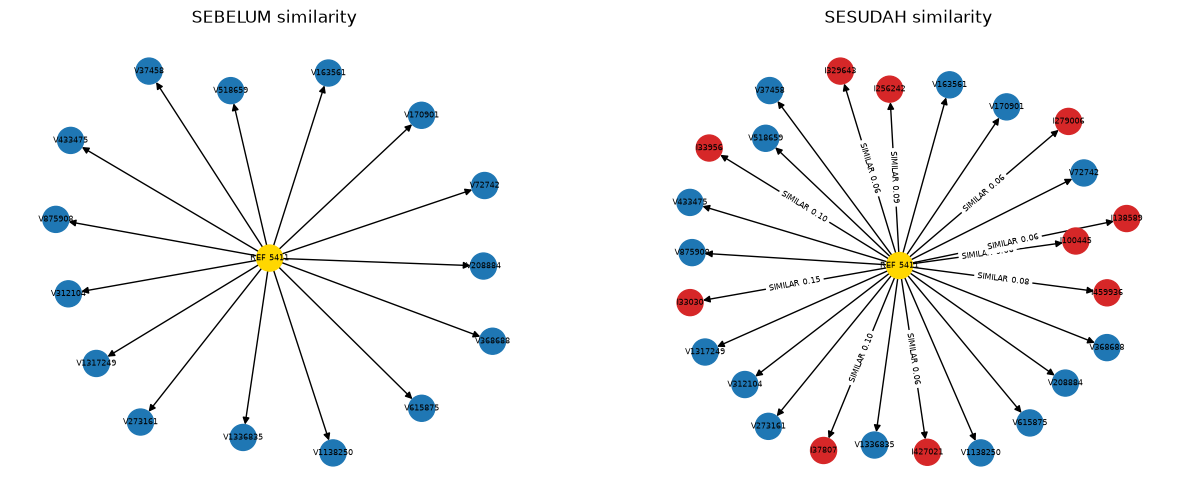

In [25]:
after_counts = rel_counts()
display(pd.concat({"sebelum": before_counts, "sesudah": after_counts}, axis=1).fillna(0).astype(int))

Q_NEI = f"MATCH (a:{C['label']} {{{C['key']}: $ref}})-[r:VIEWED|ADDED_TO_CART|BOUGHT]-(o:{C['other']}) RETURN DISTINCT o.{C['okey']} AS o, type(r) AS rel LIMIT 15"
Q_SIM = f"MATCH (a:{C['label']} {{{C['key']}: $ref}})-[s:SIMILAR]->(b) RETURN b.{C['key']} AS b, s.score AS score"
nei, sim = q(Q_NEI, ref=REF_ID), q(Q_SIM, ref=REF_ID)

def build(with_sim):
    G = nx.DiGraph(); a = f"REF {REF_ID}"
    G.add_node(a)
    for r in nei.itertuples():
        G.add_edge(a, f"{C['other'][0]}{r.o}", rel=r.rel)
    if with_sim:
        for r in sim.itertuples():
            G.add_edge(a, f"{C['label'][0]}{r.b}", rel=f"SIMILAR {r.score:.2f}")
    return G, a

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, w, title in zip(axes, [False, True], ["SEBELUM similarity", "SESUDAH similarity"]):
    G, a = build(w); pos = nx.spring_layout(G, seed=SEED)
    colors = ["gold" if n == a else ("tab:red" if G.has_edge(a, n) and "SIMILAR" in G[a][n]["rel"] else "tab:blue") for n in G]
    nx.draw(G, pos, ax=ax, node_color=colors, node_size=350, with_labels=True, font_size=6, arrows=True)
    nx.draw_networkx_edge_labels(G, pos, ax=ax, edge_labels={(u, v): d["rel"] for u, v, d in G.edges(data=True) if "SIMILAR" in d["rel"]}, font_size=6)
    ax.set_title(title)
plt.show()

## 2.2 Analytics
### Persiapan: ground truth dari P2 dan pemilihan user acak (reproducible)
- Ground truth = item pada **P2** yang **belum pernah** berinteraksi dengan user tersebut di P1 dan item-nya ada di katalog P1 (supaya bisa direkomendasikan).
- Kandidat user = user di matriks P1 yang punya ≥1 item ground truth.
- User dipilih dengan `np.random.default_rng(SEED).choice(...)` pada daftar kandidat yang diurutkan, jadi hasilnya selalu sama untuk SEED yang sama.

In [26]:
p1_df, p2_df = pd.read_csv(P1_CSV), pd.read_csv(P2_CSV)
p1_pairs = p1_df[["visitorid", "itemid"]].drop_duplicates()
p2_pairs = p2_df[["visitorid", "itemid"]].drop_duplicates()
new_pairs = (p2_pairs.merge(p1_pairs, how="left", indicator=True)
             .query("_merge == 'left_only'").drop(columns="_merge"))
new_pairs = new_pairs[new_pairs["visitorid"].isin(u_ids) & new_pairs["itemid"].isin(i_ids)]
gt_map = new_pairs.groupby("visitorid")["itemid"].apply(set).to_dict()

pool = np.sort(np.array(list(gt_map.keys())))
rng = np.random.default_rng(SEED)
target_uid = int(rng.choice(pool))
target_idx = int(u_ids.get_loc(target_uid))
print(f"Kandidat user: {len(pool):,} | user terpilih (SEED={SEED}): {target_uid}")
print("Item P1 user ini:", int(A[target_idx].nnz), "| ground truth P2:", sorted(gt_map[target_uid]))

Kandidat user: 11,022 | user terpilih (SEED=42): 123595
Item P1 user ini: 1 | ground truth P2: [20623, 96680, 101196, 111831, 134436, 144513, 148730, 184217, 184620, 263258, 317978, 319192, 356048, 374698, 425186, 437929, 462070]


### No. 1a: Skrip rekomendasi KNN (k = 5)
Mode mengikuti proyeksi terpilih di No. 6:
- **User-based KNN**: cari 5 user paling mirip (cosine), skor item = Σ similarity × bobot interaksi tetangga, item yang sudah dilihat target dibuang.
- **Item-based KNN**: untuk tiap item milik target (maks. 30 teratas menurut bobot), ambil 5 item tetangga terdekat, skor = bobot × similarity.

In [27]:
An  = normalize(A,  norm="l2")    # user x item, ter-normalisasi
Atn = normalize(At, norm="l2")    # item x user, ter-normalisasi

def recommend(u_idx, k=5, n_rec=5, mode=None):
    mode = mode or PROJ
    seen = A[u_idx].indices
    neighbors = None
    if mode == "user":
        sims = (An @ An[u_idx].T).toarray().ravel()
        sims[u_idx] = -1
        nn = np.argpartition(-sims, k)[:k]
        nn = nn[np.argsort(-sims[nn])]
        nn = nn[sims[nn] > 0]
        scores = np.asarray(A[nn].T @ sims[nn]).ravel()
        neighbors = pd.DataFrame({"visitorId": u_ids[nn], "similarity": sims[nn]})
    else:
        row = A[u_idx]
        order = np.argsort(-row.data)[:30]
        seed_items, w = row.indices[order], row.data[order]
        S = (Atn[seed_items] @ Atn.T).toarray()
        S[np.arange(len(seed_items)), seed_items] = -1
        scores = np.zeros(A.shape[1])
        for a in range(len(seed_items)):
            nb = np.argpartition(-S[a], k)[:k]
            keep = S[a, nb] > 0
            scores[nb[keep]] += w[a] * S[a, nb[keep]]
    scores[seen] = 0                                   # jangan rekomendasikan yang sudah pernah
    top = np.argsort(-scores)[:n_rec]
    top = top[scores[top] > 0]
    recs = pd.DataFrame({"rank": np.arange(1, len(top) + 1), "itemId": i_ids[top].values, "score": scores[top]})
    return recs, neighbors

recs, neighbors = recommend(target_idx, k=5, n_rec=5)
if neighbors is not None:
    print("5 tetangga terdekat (KNN, k=5):"); display(neighbors)
print("Top-5 rekomendasi:"); display(recs)

Top-5 rekomendasi:


,rank,itemId,score
0,1,330894,0.862331
1,2,121304,0.545455
2,3,63338,0.545455
3,4,186780,0.545455
4,5,273223,0.545455


### No. 1b: 3 item yang diiklankan (k = 5)

In [28]:
ads = recs.head(3)
print(f"3 item yang diiklankan untuk user {target_uid}:")
display(ads)

3 item yang diiklankan untuk user 123595:


,rank,itemId,score
0,1,330894,0.862331
1,2,121304,0.545455
2,3,63338,0.545455


### No. 2: Evaluasi Hit@5 dan NDCG@5
Evaluasi memakai daftar rekomendasi berperingkat (top-5). 3 item iklan di atas adalah 3 teratas dari daftar yang sama. Karena soal meminta @5, metrik dihitung pada 5 teratas dan @3 ditampilkan sebagai pembanding.

- **Hit@K** = 1 jika ada item ground truth di K teratas, selain itu 0.
- **DCG@K** = Σ rel_i / log₂(i+1); **NDCG@K** = DCG@K / IDCG@K, dengan rel_i = 1 jika item ke-i ada di ground truth.

In [29]:
def hit_at_k(ranked, gt, k):
    return int(len(set(ranked[:k]) & gt) > 0)

def ndcg_at_k(ranked, gt, k):
    dcg = sum(1 / np.log2(i + 2) for i, it in enumerate(ranked[:k]) if it in gt)
    idcg = sum(1 / np.log2(i + 2) for i in range(min(len(gt), k)))
    return dcg / idcg if idcg > 0 else 0.0

ranked = recs["itemId"].tolist()
gt = gt_map[target_uid]
print("Rekomendasi:", ranked)
print("Ground truth:", sorted(gt))
print(f"Hit@5  = {hit_at_k(ranked, gt, 5)}   | Hit@3  = {hit_at_k(ranked, gt, 3)}")
print(f"NDCG@5 = {ndcg_at_k(ranked, gt, 5):.4f} | NDCG@3 = {ndcg_at_k(ranked, gt, 3):.4f}")

Rekomendasi: [330894, 121304, 63338, 186780, 273223]
Ground truth: [20623, 96680, 101196, 111831, 134436, 144513, 148730, 184217, 184620, 263258, 317978, 319192, 356048, 374698, 425186, 437929, 462070]
Hit@5  = 0   | Hit@3  = 0
NDCG@5 = 0.0000 | NDCG@3 = 0.0000


### coba: rata-rata metrik pada 200 user acak


In [30]:
sample_users = np.random.default_rng(SEED).choice(pool, size=min(200, len(pool)), replace=False)
hits, ndcgs = [], []
for uid in tqdm(sample_users):
    r, _ = recommend(int(u_ids.get_loc(int(uid))), k=5, n_rec=5)
    lst = r["itemId"].tolist(); g = gt_map[int(uid)]
    hits.append(hit_at_k(lst, g, 5)); ndcgs.append(ndcg_at_k(lst, g, 5))
print(f"Rata-rata pada {len(sample_users)} user | Hit@5 = {np.mean(hits):.4f} | NDCG@5 = {np.mean(ndcgs):.4f}")

  0%|          | 0/200 [00:00<?, ?it/s]

Rata-rata pada 200 user | Hit@5 = 0.0050 | NDCG@5 = 0.0025


In [31]:
driver.close()